# Task 8 - root segmentation and measurement

Two parts. First a U-Net is trained to segment plant roots from the dish images (patch based, with augmentation). Then the trained model is run on the test images to detect up to five plants per dish and measure each primary root length in pixels, written out to a CSV.

Runs on Colab with a GPU.


✓ GPU ready: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train: 473 image-mask pairs
Val  : 17   image-mask pairs
Pairing OK
Extracting ALL train patches...
  → 39162 patches from 473 train images
Extracting ALL val patches...
  → 861 patches from 17 val images
Converting to numpy arrays...
Train array: (39162, 256, 256, 1)
Val array  : (861, 256, 256, 1)
Train: 1224 batches (39162 patches)
Val  : 27 batches (861 patches)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 256, 256,  │        640 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_38[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_36       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 256, 256,  │     36,928 │ activation_36[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        256 │ conv2d_39[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_37       │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 128, 128,  │          0 │ activation_37[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 128, 128,  │     73,856 │ max_pooling2d_8[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_40[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_38       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 128, 128,  │    147,584 │ activation_38[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_41[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_39       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 64, 64,    │          0 │ activation_39[0]… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 64, 64,    │    295,168 │ max_pooling2d_9[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │      1,024 │ conv2d_42[0][0] 

 Total params: 31,054,145 (118.46 MB)

 Trainable params: 31,042,369 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

Epoch 1/40
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - f1: 0.6186 - loss: 0.3725
Epoch 1: val_f1 improved from None to 0.80250, saving model to jaberiiii_244437_unet_model_256px.keras

Epoch 1: finished saving model to jaberiiii_244437_unet_model_256px.keras
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 624s 451ms/step - f1: 0.7119 - loss: 0.2707 - val_f1: 0.8025 - val_loss: 0.1534 - learning_rate: 1.0000e-04
Epoch 2/40
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - f1: 0.7834 - loss: 0.1517
Epoch 2: val_f1 improved from 0.80250 to 0.83772, saving model to jaberiiii_244437_unet_model_256px.keras

Epoch 2: finished saving model to jaberiiii_244437_unet_model_256px.keras
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 489s 399ms/step - f1: 0.7910 - loss: 0.1423 - val_f1: 0.8377 - val_loss: 0.1046 - learning_rate: 1.0000e-04
Epoch 3/40
1224/1224 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - f1: 0.8014 - loss: 0.1280
Epoch 3: val_f1 improved from 0.83772 to 0.85134, saving model to jaberiiii_244437_unet_model_256px.keras

Epoc

Best validation loss: 0.07587318867444992
Best validation f1  : 0.871420681476593
MoaliJaberiiii_244437_unet_model_256px.h5


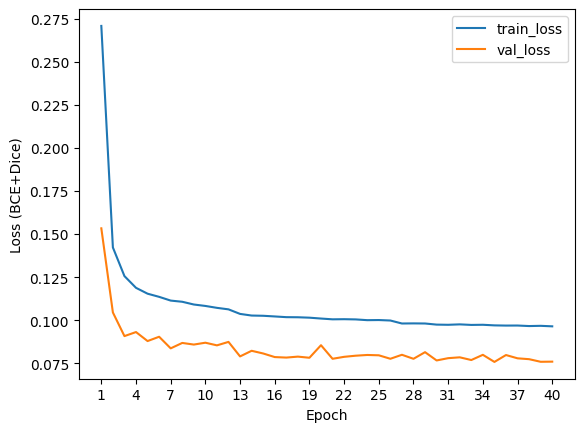

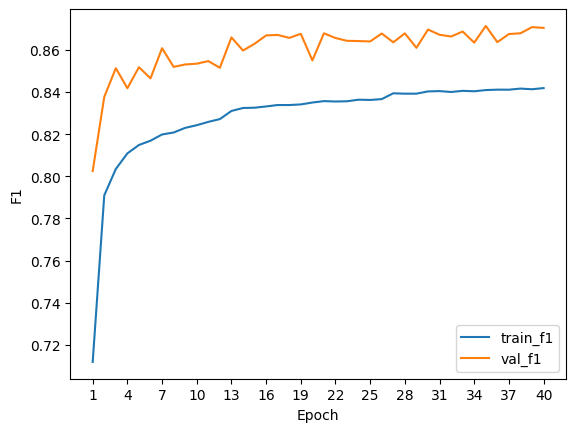

In [ ]:
# ============================================================
# CELL 1, Imports
# ============================================================
import os
import numpy as np
import cv2
import glob as glob_mod
import random
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, gaussian_filter
from tensorflow.keras import backend as K
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.utils import Sequence
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


# ============================================================
# CELL 2, GPU check + setup
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU ready: {gpus}")
else:
    print("No GPU found, go to Runtime -> Change runtime type -> T4 GPU")


# ============================================================
# CELL 3, Config
# ============================================================
MODEL_INPUT_SIZE = 256
BATCH_SIZE       = 32
EPOCHS           = 40
MIN_ROOT_PIXELS  = 10
PATCH_SIZE       = 256
STRIDE           = 192

train_img_dir = '/content/Block_B_retake/train_images'
train_msk_dir = '/content/Block_B_retake/train_masks'
val_img_dir   = '/content/Block_B_retake/val_images'
val_msk_dir   = '/content/Block_B_retake/val_masks'


# ============================================================
# CELL 4, Pair images with root masks
# ============================================================
def get_paired_paths(img_dir, msk_dir):
    img_paths = sorted(glob_mod.glob(os.path.join(img_dir, '*.png')))
    paired_imgs, paired_msks = [], []
    missing = 0
    for ip in img_paths:
        stem     = os.path.splitext(os.path.basename(ip))[0]
        msk_path = os.path.join(msk_dir, stem + '_root_mask.tif')
        if os.path.exists(msk_path):
            paired_imgs.append(ip)
            paired_msks.append(msk_path)
        else:
            missing += 1
    if missing:
        print(f"  INFO: {missing} images skipped (no root mask)")
    return paired_imgs, paired_msks

train_imgs, train_msks = get_paired_paths(train_img_dir, train_msk_dir)
val_imgs,   val_msks   = get_paired_paths(val_img_dir,   val_msk_dir)

print(f"Train: {len(train_imgs)} image-mask pairs")
print(f"Val  : {len(val_imgs)}   image-mask pairs")
assert len(train_imgs) > 0 and len(val_imgs) > 0
print("Pairing OK")


# ============================================================
# CELL 5, Extract ALL patches
# ============================================================
def extract_all_patches(img_path, msk_path,
                        patch_size=PATCH_SIZE,
                        stride=STRIDE,
                        min_root_px=MIN_ROOT_PIXELS,
                        bg_keep_rate=0.15):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
    msk = cv2.imread(msk_path, cv2.IMREAD_GRAYSCALE).astype(np.float32)
    msk = (msk > 0).astype(np.float32)
    H, W = img.shape
    patches_img, patches_msk = [], []
    for r in range(0, H - patch_size + 1, stride):
        for c in range(0, W - patch_size + 1, stride):
            pi = img[r:r+patch_size, c:c+patch_size]
            pm = msk[r:r+patch_size, c:c+patch_size]
            has_root = np.sum(pm) >= min_root_px
            if has_root or random.random() < bg_keep_rate:
                patches_img.append(pi[..., np.newaxis].astype(np.float32))
                patches_msk.append(pm[..., np.newaxis].astype(np.float32))
    return patches_img, patches_msk


def build_full_dataset(img_paths, msk_paths, stride, label='train'):
    all_imgs, all_msks = [], []
    for ip, mp in zip(img_paths, msk_paths):
        pi_list, pm_list = extract_all_patches(ip, mp, stride=stride)
        all_imgs.extend(pi_list)
        all_msks.extend(pm_list)
    print(f"  -> {len(all_imgs)} patches from {len(img_paths)} {label} images")
    return all_imgs, all_msks


print("Extracting ALL train patches...")
train_patch_imgs, train_patch_msks = build_full_dataset(
    train_imgs, train_msks, stride=STRIDE, label='train')

print("Extracting ALL val patches...")
val_patch_imgs, val_patch_msks = build_full_dataset(
    val_imgs, val_msks, stride=PATCH_SIZE, label='val')

print("Converting to numpy arrays...")
train_patch_imgs = np.array(train_patch_imgs, dtype=np.float32)
train_patch_msks = np.array(train_patch_msks, dtype=np.float32)
val_patch_imgs   = np.array(val_patch_imgs,   dtype=np.float32)
val_patch_msks   = np.array(val_patch_msks,   dtype=np.float32)
print(f"Train array: {train_patch_imgs.shape}")
print(f"Val array  : {val_patch_imgs.shape}")


# ============================================================
# CELL 6, Enhanced augmentation
# ============================================================
def elastic_deform(img, msk, alpha=12, sigma=8):
    shape = img.shape[:2]
    dx = gaussian_filter(np.random.randn(*shape), sigma) * alpha
    dy = gaussian_filter(np.random.randn(*shape), sigma) * alpha
    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    coords = [
        np.clip(y + dy, 0, shape[0] - 1),
        np.clip(x + dx, 0, shape[1] - 1)
    ]
    img_d = map_coordinates(img[..., 0], coords, order=1).astype(np.float32)
    msk_d = map_coordinates(msk[..., 0], coords, order=0).astype(np.float32)
    return img_d[..., np.newaxis], msk_d[..., np.newaxis]


def augment_patch(img, msk):
    # Geometric
    if random.random() > 0.5:
        img = np.fliplr(img); msk = np.fliplr(msk)
    if random.random() > 0.5:
        img = np.flipud(img); msk = np.flipud(msk)
    k = random.randint(0, 3)
    if k > 0:
        img = np.rot90(img[:,:,0], k)[:,:,np.newaxis]
        msk = np.rot90(msk[:,:,0], k)[:,:,np.newaxis]
    if random.random() > 0.5:
        img, msk = elastic_deform(img, msk, alpha=12, sigma=8)

    # Photometric
    if random.random() > 0.5:
        img = np.clip(img * random.uniform(0.75, 1.25), 0, 1)
    if random.random() > 0.5:
        gamma = random.uniform(0.7, 1.5)
        img = np.clip(img ** gamma, 0, 1)
    if random.random() > 0.5:
        mean = img.mean()
        img = np.clip((img - mean) * random.uniform(0.8, 1.2) + mean, 0, 1)
    if random.random() > 0.5:
        noise = np.random.normal(0, 0.02, img.shape).astype(np.float32)
        img = np.clip(img + noise, 0, 1)

    return img.astype(np.float32), (msk > 0.5).astype(np.float32)


# ============================================================
# CELL 7, Generator
# ============================================================
class SegGenerator(Sequence):
    def __init__(self, img_patches, msk_patches,
                 batch_size=32, augment=False, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.imgs       = img_patches
        self.msks       = msk_patches
        self.batch_size = batch_size
        self.augment    = augment
        self.shuffle    = shuffle
        self.indices    = np.arange(len(self.imgs))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.imgs) / self.batch_size))

    def __getitem__(self, index):
        batch_idx = self.indices[index*self.batch_size:(index+1)*self.batch_size]
        imgs = self.imgs[batch_idx].copy()
        msks = self.msks[batch_idx].copy()
        if self.augment:
            for i in range(len(imgs)):
                imgs[i], msks[i] = augment_patch(imgs[i], msks[i])
        return imgs, msks

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


train_generator = SegGenerator(
    train_patch_imgs, train_patch_msks,
    batch_size=BATCH_SIZE, augment=True, shuffle=True)

val_generator = SegGenerator(
    val_patch_imgs, val_patch_msks,
    batch_size=BATCH_SIZE, augment=False, shuffle=False)

print(f"Train: {len(train_generator)} batches ({len(train_patch_imgs)} patches)")
print(f"Val  : {len(val_generator)} batches ({len(val_patch_imgs)} patches)")


# ============================================================
# CELL 8, Metrics & Losses
# ============================================================
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        return TP / (Positives + K.epsilon())
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        return TP / (Pred_Positives + K.epsilon())
    p = precision_m(y_true, y_pred)
    r = recall_m(y_true, y_pred)
    return 2 * ((p * r) / (p + r + K.epsilon()))


def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth)


def bce_dice_loss(y_true, y_pred):
    # Root pixels weighted 3x, forces model to focus on thin roots
    weight        = 1.0 + 2.0 * y_true
    bce_per_pixel = tf.keras.losses.binary_crossentropy(y_true, y_pred, axis=-1)
    weighted_bce  = tf.reduce_mean(weight[..., 0] * bce_per_pixel)
    return 0.5 * weighted_bce + 0.5 * dice_loss(y_true, y_pred)


# ============================================================
# CELL 9, Full U-Net (64/128/256/512/1024)
# ============================================================
def conv_block(x, filters, dropout_rate=0.0):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    return x

def simple_unet_model(input_shape=(256, 256, 1)):
    inputs = layers.Input(shape=input_shape)
    c1 = conv_block(inputs, 64);        p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 128);           p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 256);           p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 512, 0.3);      p4 = layers.MaxPooling2D()(c4)
    bn = conv_block(p4, 1024, 0.5)
    u1 = layers.Conv2DTranspose(512, 2, strides=2, padding='same')(bn)
    u1 = layers.concatenate([u1, c4]);  c5 = conv_block(u1, 512, 0.3)
    u2 = layers.Conv2DTranspose(256, 2, strides=2, padding='same')(c5)
    u2 = layers.concatenate([u2, c3]);  c6 = conv_block(u2, 256)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c6)
    u3 = layers.concatenate([u3, c2]);  c7 = conv_block(u3, 128)
    u4 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c7)
    u4 = layers.concatenate([u4, c1]);  c8 = conv_block(u4, 64)
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c8)
    return models.Model(inputs, outputs)

model = simple_unet_model()
model.summary()


# ============================================================
# CELL 10, Callbacks & Compile
# ============================================================
early_stop = EarlyStopping(
    monitor='val_f1', mode='max',
    patience=20, restore_best_weights=True, verbose=1)

checkpoint = ModelCheckpoint(
    "jaberiiii_244437_unet_model_256px.keras",
    monitor='val_f1', mode='max',
    save_best_only=True, verbose=1)

reduce_lr = ReduceLROnPlateau(
    monitor='val_f1', mode='max',
    factor=0.5, patience=5, min_lr=1e-6, verbose=1)

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,
    metrics=[f1])


# ============================================================
# CELL 11, Training
# ============================================================
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint, reduce_lr])


# ============================================================
# CELL 12, Best scores  (REQUIREMENT: Do not change)
# ============================================================
best_val_loss = min(history.history['val_loss'])
best_val_f1   = max(history.history['val_f1'])
print(f"Best validation loss: {best_val_loss}")
print(f"Best validation f1  : {best_val_f1}")


# ============================================================
# CELL 13, Save model  (REQUIREMENT: naming convention)
# ============================================================
patch_size = 256
example_file_name = f'MoaliJaberiiii_244437_unet_model_{patch_size}px.h5'
model.save(example_file_name)
print(example_file_name)


# ============================================================
# CELL 14, Loss plot  (REQUIREMENT: Do not change)
# ============================================================
loss_h     = history.history['loss']
val_loss_h = history.history['val_loss']
epochs_r   = np.arange(1, len(loss_h) + 1)

plt.plot(epochs_r, loss_h,     label='train_loss')
plt.plot(epochs_r, val_loss_h, label='val_loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss (BCE+Dice)')
_ = plt.xticks(np.arange(1, len(loss_h) + 1, 3))


# ============================================================
# CELL 15, F1 plot  (REQUIREMENT: Do not change)
# ============================================================
train_f1_h = history.history['f1']
val_f1_h   = history.history['val_f1']

plt.figure()
plt.plot(epochs_r, train_f1_h, label='train_f1')
plt.plot(epochs_r, val_f1_h,   label='val_f1')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('F1')
_ = plt.xticks(np.arange(1, len(loss_h) + 1, 3))

## Part 2 - inference and root measurement

Load the trained model, run it patch by patch over each full test image, detect the plants with connected components, and measure the primary root of each plant by skeletonizing the mask and taking the longest path. Results go to a CSV plus an overlay image per dish.


In [ ]:
#  ============================================================
# Root Measurement Pipeline
# Loads trained U-Net -> predicts masks on full test images
# -> detects 5 plants per image -> measures primary root length
# -> saves results to CSV
# ============================================================

# ============================================================
# CELL 1, Install dependencies (run once)
# ============================================================
# !pip install scikit-image -q


# ============================================================
# CELL 2, Imports
# ============================================================
import os
import numpy as np
import cv2
import glob as glob_mod
import pandas as pd
from tensorflow.keras.models import load_model
from tensorflow.keras import backend as K
import tensorflow as tf
from skimage.morphology import skeletonize
from skimage.measure import label, regionprops
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# ============================================================
# CELL 3, Config
# ============================================================
MODEL_PATH     = '/content/jaberiiii_2444377_unet_model_256px.keras'
TEST_IMG_DIR   = '/content/drive/MyDrive/BSp-2B Computer Vision & Robotics 2025-2026 Team - Datasets/Kaggle'
OUTPUT_CSV     = 'root_lengths200.csv'
OUTPUT_VIS_DIR = 'root_visualizations'
PATCH_SIZE     = 256
THRESHOLD      = 0.5
N_PLANTS       = 5

os.makedirs(OUTPUT_VIS_DIR, exist_ok=True)


# ============================================================

# CELL 4, Load model
# ============================================================
def f1(y_true, y_pred):
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        return TP / (Positives + K.epsilon())
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        return TP / (Pred_Positives + K.epsilon())
    p = precision_m(y_true, y_pred)
    r = recall_m(y_true, y_pred)
    return 2 * ((p * r) / (p + r + K.epsilon()))

def dice_loss(y_true, y_pred):
    smooth = 1e-6
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return 1 - (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    weight        = 1.0 + 2.0 * y_true
    bce_per_pixel = tf.keras.losses.binary_crossentropy(y_true, y_pred, axis=-1)
    weighted_bce  = tf.reduce_mean(weight[..., 0] * bce_per_pixel)
    return 0.5 * weighted_bce + 0.5 * dice_loss(y_true, y_pred)

model = load_model(MODEL_PATH, custom_objects={
    'f1': f1,
    'bce_dice_loss': bce_dice_loss
})
print("Model loaded OK")


# ============================================================
# CELL 5, Full image inference (patch-by-patch stitching)
#
# Tiles the full image into 256x256 patches, runs the model
# on all patches in one batch, then stitches back together.
# ============================================================
def predict_full_image(model, img_path,
                       patch_size=PATCH_SIZE, threshold=THRESHOLD):
    img_orig = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    H, W     = img_orig.shape
    img      = img_orig.astype(np.float32) / 255.0

    # Pad so dimensions are divisible by patch_size
    pad_h = (patch_size - H % patch_size) % patch_size
    pad_w = (patch_size - W % patch_size) % patch_size
    img_pad = np.pad(img, ((0, pad_h), (0, pad_w)), mode='reflect')
    H_pad, W_pad = img_pad.shape

    # Collect all patches
    patches, coords = [], []
    for r in range(0, H_pad, patch_size):
        for c in range(0, W_pad, patch_size):
            patches.append(img_pad[r:r+patch_size, c:c+patch_size][..., np.newaxis])
            coords.append((r, c))

    patches = np.array(patches, dtype=np.float32)
    preds   = model.predict(patches, batch_size=16, verbose=0)

    # Stitch predictions back
    pred_pad = np.zeros((H_pad, W_pad), dtype=np.float32)
    for i, (r, c) in enumerate(coords):
        pred_pad[r:r+patch_size, c:c+patch_size] = preds[i, :, :, 0]

    pred        = pred_pad[:H, :W]
    binary_mask = (pred > threshold).astype(np.uint8)
    return img_orig, binary_mask


# ============================================================
# CELL 6, Detect 5 plants via connected components
#
# 1. Find all connected components in the binary mask
# 2. Filter out tiny noise blobs (< min_area pixels)
# 3. If more than N_PLANTS found -> keep N_PLANTS largest
# 4. Sort left -> right by x centroid = plant_1 to plant_5
# ============================================================
def detect_plants(binary_mask, n_plants=N_PLANTS, min_area=200):
    # Morphological closing to connect nearby root fragments
    kernel  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    cleaned = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

    labeled = label(cleaned, connectivity=2)
    props   = regionprops(labeled)

    # Remove tiny noise components
    props = [p for p in props if p.area >= min_area]

    if len(props) == 0:
        return None, labeled

    # If more than n_plants detected, keep the n_plants largest
    if len(props) > n_plants:
        props = sorted(props, key=lambda p: p.area, reverse=True)[:n_plants]

    # Sort left to right (plant_1 = leftmost, plant_5 = rightmost)
    props = sorted(props, key=lambda p: p.centroid[1])

    return props, labeled


# ============================================================
# CELL 7, Measure primary root length via skeletonization
#
# Primary root = longest connected path from the topmost point
# of the plant skeleton, traced downward.
#
# Steps:
#   1. Skeletonize the plant mask -> 1-pixel-wide lines
#   2. Build a graph of connected skeleton pixels
#   3. Start from the topmost pixel (shoot base)
#   4. DFS to find the longest weighted path (diagonal = sqrt(2))
# ============================================================
def measure_primary_root(plant_mask):
    """
    Fast primary root length using skeletonization + BFS diameter.

    Instead of slow recursive DFS, we use two-pass BFS:
      1. BFS from topmost pixel -> finds the farthest endpoint
      2. BFS from that endpoint -> distance to farthest point = diameter
    This runs in O(N) time instead of exponential DFS.
    """
    if plant_mask.sum() < 10:
        return 0.0

    skel = skeletonize(plant_mask > 0)
    if skel.sum() == 0:
        return 0.0

    rows, cols = np.where(skel)
    if len(rows) == 0:
        return 0.0

    # Build adjacency as dict for O(1) lookup
    pixel_set = set(zip(rows.tolist(), cols.tolist()))

    def bfs_farthest(start):
        """BFS returning (farthest_node, distance) from start."""
        from collections import deque
        visited = {start: 0.0}
        queue   = deque([start])
        farthest, max_dist = start, 0.0
        while queue:
            node = queue.popleft()
            r, c = node
            d    = visited[node]
            for dr in [-1, 0, 1]:
                for dc in [-1, 0, 1]:
                    if dr == 0 and dc == 0:
                        continue
                    nb = (r + dr, c + dc)
                    if nb in pixel_set and nb not in visited:
                        step = np.sqrt(dr**2 + dc**2)
                        visited[nb] = d + step
                        queue.append(nb)
                        if visited[nb] > max_dist:
                            max_dist = visited[nb]
                            farthest = nb
        return farthest, max_dist

    # Start from topmost pixel (shoot base)
    start         = min(pixel_set, key=lambda p: p[0])
    far1, _       = bfs_farthest(start)   # find one end of diameter
    _, length     = bfs_farthest(far1)    # measure from that end
    return round(length, 1)


# ============================================================
# CELL 8, Save visualisation overlay per image
# ============================================================
def save_visualization(img_orig, binary_mask, plant_props,
                       labeled, lengths, img_name, out_dir):
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    axes[0].imshow(img_orig, cmap='gray')
    axes[0].set_title('Original')
    axes[0].axis('off')

    overlay = cv2.cvtColor(img_orig, cv2.COLOR_GRAY2RGB)
    overlay[binary_mask > 0] = [220, 80, 80]

    axes[1].imshow(overlay)
    colors = ['#e63946', '#2a9d8f', '#e9c46a', '#4361ee', '#f77f00']

    for i, (prop, length) in enumerate(zip(plant_props, lengths)):
        minr, minc, maxr, maxc = prop.bbox
        color = colors[i % len(colors)]
        rect  = mpatches.Rectangle(
            (minc, minr), maxc - minc, maxr - minr,
            linewidth=2, edgecolor=color, facecolor='none')
        axes[1].add_patch(rect)
        axes[1].text(
            minc, max(minr - 8, 10),
            f'Plant {i+1}: {length}px',
            color=color, fontsize=9, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.7, pad=2, edgecolor='none'))

    axes[1].set_title('Detected plants + primary root lengths')
    axes[1].axis('off')
    plt.tight_layout()

    out_path = os.path.join(out_dir, img_name.replace('.png', '_vis.png'))
    plt.savefig(out_path, dpi=100, bbox_inches='tight')
    plt.close()
    print(f"  Saved: {out_path}")


# ============================================================
# CELL 9, Main loop: process all test images
# ============================================================
test_imgs = sorted(glob_mod.glob(os.path.join(TEST_IMG_DIR, '*.png')))
print(f"Found {len(test_imgs)} test images\n")
assert len(test_imgs) > 0, "No test images found, check TEST_IMG_DIR"

results = []

for img_path in test_imgs:
    img_name = os.path.basename(img_path)
    img_stem = os.path.splitext(img_name)[0]
    print(f"Processing: {img_name}")

    # Step 1, predict mask
    img_orig, binary_mask = predict_full_image(model, img_path)

    # Step 2, detect plants
    plant_props, labeled = detect_plants(binary_mask, n_plants=N_PLANTS)

    if plant_props is None or len(plant_props) == 0:
        print(f"  WARNING: no plants detected -> all lengths = 0")
        for p in range(1, N_PLANTS + 1):
            results.append({'Plant ID': f'{img_stem}_plant_{p}',
                            'Length (px)': 0})
        continue

    print(f"  Detected {len(plant_props)} plant(s)")

    # Step 3, measure each plant
    lengths = []
    for i, prop in enumerate(plant_props):
        plant_mask = (labeled == prop.label).astype(np.uint8)
        length     = measure_primary_root(plant_mask)
        lengths.append(length)
        print(f"  Plant {i+1}: {length} px")
        results.append({'Plant ID': f'{img_stem}_plant_{i+1}',
                        'Length (px)': length})

    # Fill missing plants with 0
    for p in range(len(plant_props) + 1, N_PLANTS + 1):
        print(f"  Plant {p}: not detected -> 0 px")
        results.append({'Plant ID': f'{img_stem}_plant_{p}',
                        'Length (px)': 0})
    print()


# ============================================================
# CELL 10, Save CSV
# ============================================================
df = pd.DataFrame(results)
df.to_csv(OUTPUT_CSV, index=False)

print("=" * 40)
print(f"Done! CSV saved to: {OUTPUT_CSV}")
print(f"Visualizations saved to: {OUTPUT_VIS_DIR}/")
print("=" * 40)
print(df.to_string())

✓ Model loaded OK
Found 19 test images

Processing: test_image_01.png
  Detected 5 plant(s)
  Plant 1: 855.0 px
  Plant 2: 1498.1 px
  Plant 3: 470.6 px
  Plant 4: 1846.0 px
  Plant 5: 1621.8 px

Processing: test_image_02.png
  Detected 5 plant(s)
  Plant 1: 1313.8 px
  Plant 2: 1480.4 px
  Plant 3: 941.0 px
  Plant 4: 1060.2 px
  Plant 5: 1073.0 px

Processing: test_image_03.png
  Detected 5 plant(s)
  Plant 1: 132.7 px
  Plant 2: 80.9 px
  Plant 3: 130.4 px
  Plant 4: 166.5 px
  Plant 5: 42.3 px

Processing: test_image_04.png
  Detected 5 plant(s)
  Plant 1: 256.7 px
  Plant 2: 1185.8 px
  Plant 3: 1021.9 px
  Plant 4: 1089.4 px
  Plant 5: 1123.8 px

Processing: test_image_05.png
  Detected 4 plant(s)
  Plant 1: 143.0 px
  Plant 2: 49.0 px
  Plant 3: 108.5 px
  Plant 4: 100.3 px
  Plant 5: not detected → 0 px

Processing: test_image_06.png
  Detected 5 plant(s)
  Plant 1: 255.5 px
  Plant 2: 226.8 px
  Plant 3: 71.0 px
  Plant 4: 206.1 px
  Plant 5: 201.4 px

Processing: test_image_0